# 01 — Pose-quality audit of Notebook 1 keypoints

Read-only audit of `data/processed/keypoints_batch_all/*.npz`. This does not import YOLO or PyTorch, does not run ViTPose, and never modifies original NPZ files.

It creates per-video and per-class CSVs plus a contact sheet using a small number of original frames.

In [1]:
from pathlib import Path
import json, gc
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
NOTEBOOK2_DIR = PROJECT_DIR / "Notebook_2_Improved_v2"
KEYPOINT_DIR = PROJECT_DIR / "data" / "processed" / "keypoints_batch_all"
REPORT_DIR = NOTEBOOK2_DIR / "outputs" / "reports" / "pose_quality_audit_v2"
VIS_DIR = NOTEBOOK2_DIR / "outputs" / "visualizations" / "pose_quality_audit_v2"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
VIS_DIR.mkdir(parents=True, exist_ok=True)
assert KEYPOINT_DIR.is_dir(), f"Original keypoint directory not found: {KEYPOINT_DIR}"
npz_files = sorted(p for p in KEYPOINT_DIR.glob("*.npz") if ".partial." not in p.name and ".tmp." not in p.name)
print("Completed NPZ files:", len(npz_files))

Completed NPZ files: 13319


In [2]:
records, errors = [], []
for i, path in enumerate(npz_files, 1):
    try:
        with np.load(path, allow_pickle=False) as d:
            required = {"keypoints", "boxes", "frame_indices", "has_person", "label", "video_path"}
            missing = required - set(d.files)
            if missing:
                raise ValueError(f"Missing keys: {sorted(missing)}")
            kps = np.asarray(d["keypoints"], dtype=np.float32)
            boxes = np.asarray(d["boxes"], dtype=np.float32)
            frame_idx = np.asarray(d["frame_indices"], dtype=np.int64)
            has_person = np.asarray(d["has_person"], dtype=bool)
            detection_found = np.asarray(d["detection_found"], dtype=bool) if "detection_found" in d.files else has_person.copy()
            label = str(d["label"].item())
            video_path = str(d["video_path"].item())
            track_ids_available = "track_ids" in d.files
        if kps.ndim != 3 or kps.shape[1:] != (17,3):
            raise ValueError(f"Unexpected keypoint shape: {kps.shape}")
        n = len(kps)
        if not (len(boxes)==len(frame_idx)==len(has_person)==len(detection_found)==n):
            raise ValueError("Array lengths do not match")
        finite_xy = np.isfinite(kps[:,:,:2]).all(axis=2)
        finite_joint_counts = finite_xy.sum(axis=1)
        valid_box = np.isfinite(boxes).all(axis=1) & ((boxes[:,2]-boxes[:,0])>=2) & ((boxes[:,3]-boxes[:,1])>=2)
        conf = kps[:,:,2]
        conf_finite = np.isfinite(conf)
        mean_conf = float(np.nanmean(np.where(conf_finite, conf, np.nan))) if conf_finite.any() else np.nan
        records.append({
            "npz_path": str(path), "video_path": video_path, "label": label,
            "sampled_frames": n,
            "detection_rate": float(detection_found.mean()) if n else 0.0,
            "has_person_rate": float(has_person.mean()) if n else 0.0,
            "mean_finite_joints": float(finite_joint_counts.mean()) if n else 0.0,
            "frames_with_at_least_8_finite_joints": int((finite_joint_counts>=8).sum()),
            "valid_box_rate": float(valid_box.mean()) if n else 0.0,
            "mean_confidence_raw": mean_conf,
            "track_ids_available": track_ids_available,
        })
    except Exception as exc:
        errors.append({"npz_path":str(path), "error":repr(exc)})
    if i % 1000 == 0:
        print(f"Scanned {i} / {len(npz_files)}")

summary = pd.DataFrame(records)
assert not summary.empty, "No readable original NPZ files were found."
summary_path = REPORT_DIR / "pose_quality_video_summary.csv"
summary.to_csv(summary_path, index=False)
class_summary = summary.groupby("label").agg(
    videos=("video_path","nunique"),
    mean_detection_rate=("detection_rate","mean"),
    mean_pose_rate=("has_person_rate","mean"),
    mean_finite_joints=("mean_finite_joints","mean"),
    mean_valid_box_rate=("valid_box_rate","mean"),
    mean_confidence_raw=("mean_confidence_raw","mean"),
).sort_values("mean_pose_rate")
class_path = REPORT_DIR / "pose_quality_class_summary.csv"
class_summary.to_csv(class_path)
if errors:
    pd.DataFrame(errors).to_csv(REPORT_DIR / "pose_quality_unreadable_files.csv", index=False)
print("Readable videos:", len(summary), "| unreadable NPZ:", len(errors))
print("Video report:", summary_path)
print("Class report:", class_path)
print("Lowest pose-rate classes:\n", class_summary.head(15).to_string())

Scanned 1000 / 13319
Scanned 2000 / 13319
Scanned 3000 / 13319
Scanned 4000 / 13319
Scanned 5000 / 13319
Scanned 6000 / 13319
Scanned 7000 / 13319
Scanned 8000 / 13319
Scanned 9000 / 13319
Scanned 10000 / 13319
Scanned 11000 / 13319
Scanned 12000 / 13319
Scanned 13000 / 13319
Readable videos: 13319 | unreadable NPZ: 0
Video report: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\reports\pose_quality_audit_v2\pose_quality_video_summary.csv
Class report: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\reports\pose_quality_audit_v2\pose_quality_class_summary.csv
Lowest pose-rate classes:
                     videos  mean_detection_rate  mean_pose_rate  mean_finite_joints  mean_valid_box_rate  mean_confidence_raw
label                                                                                                                        
BreastStroke           101             0.231174        0.231174            3.929957             0.231174 

## Contact sheet

A frame with successful `has_person=True` is selected where possible. This is a visual inspection aid, not a pose-accuracy benchmark. Raw heatmap confidence values should not be treated as calibrated probabilities.

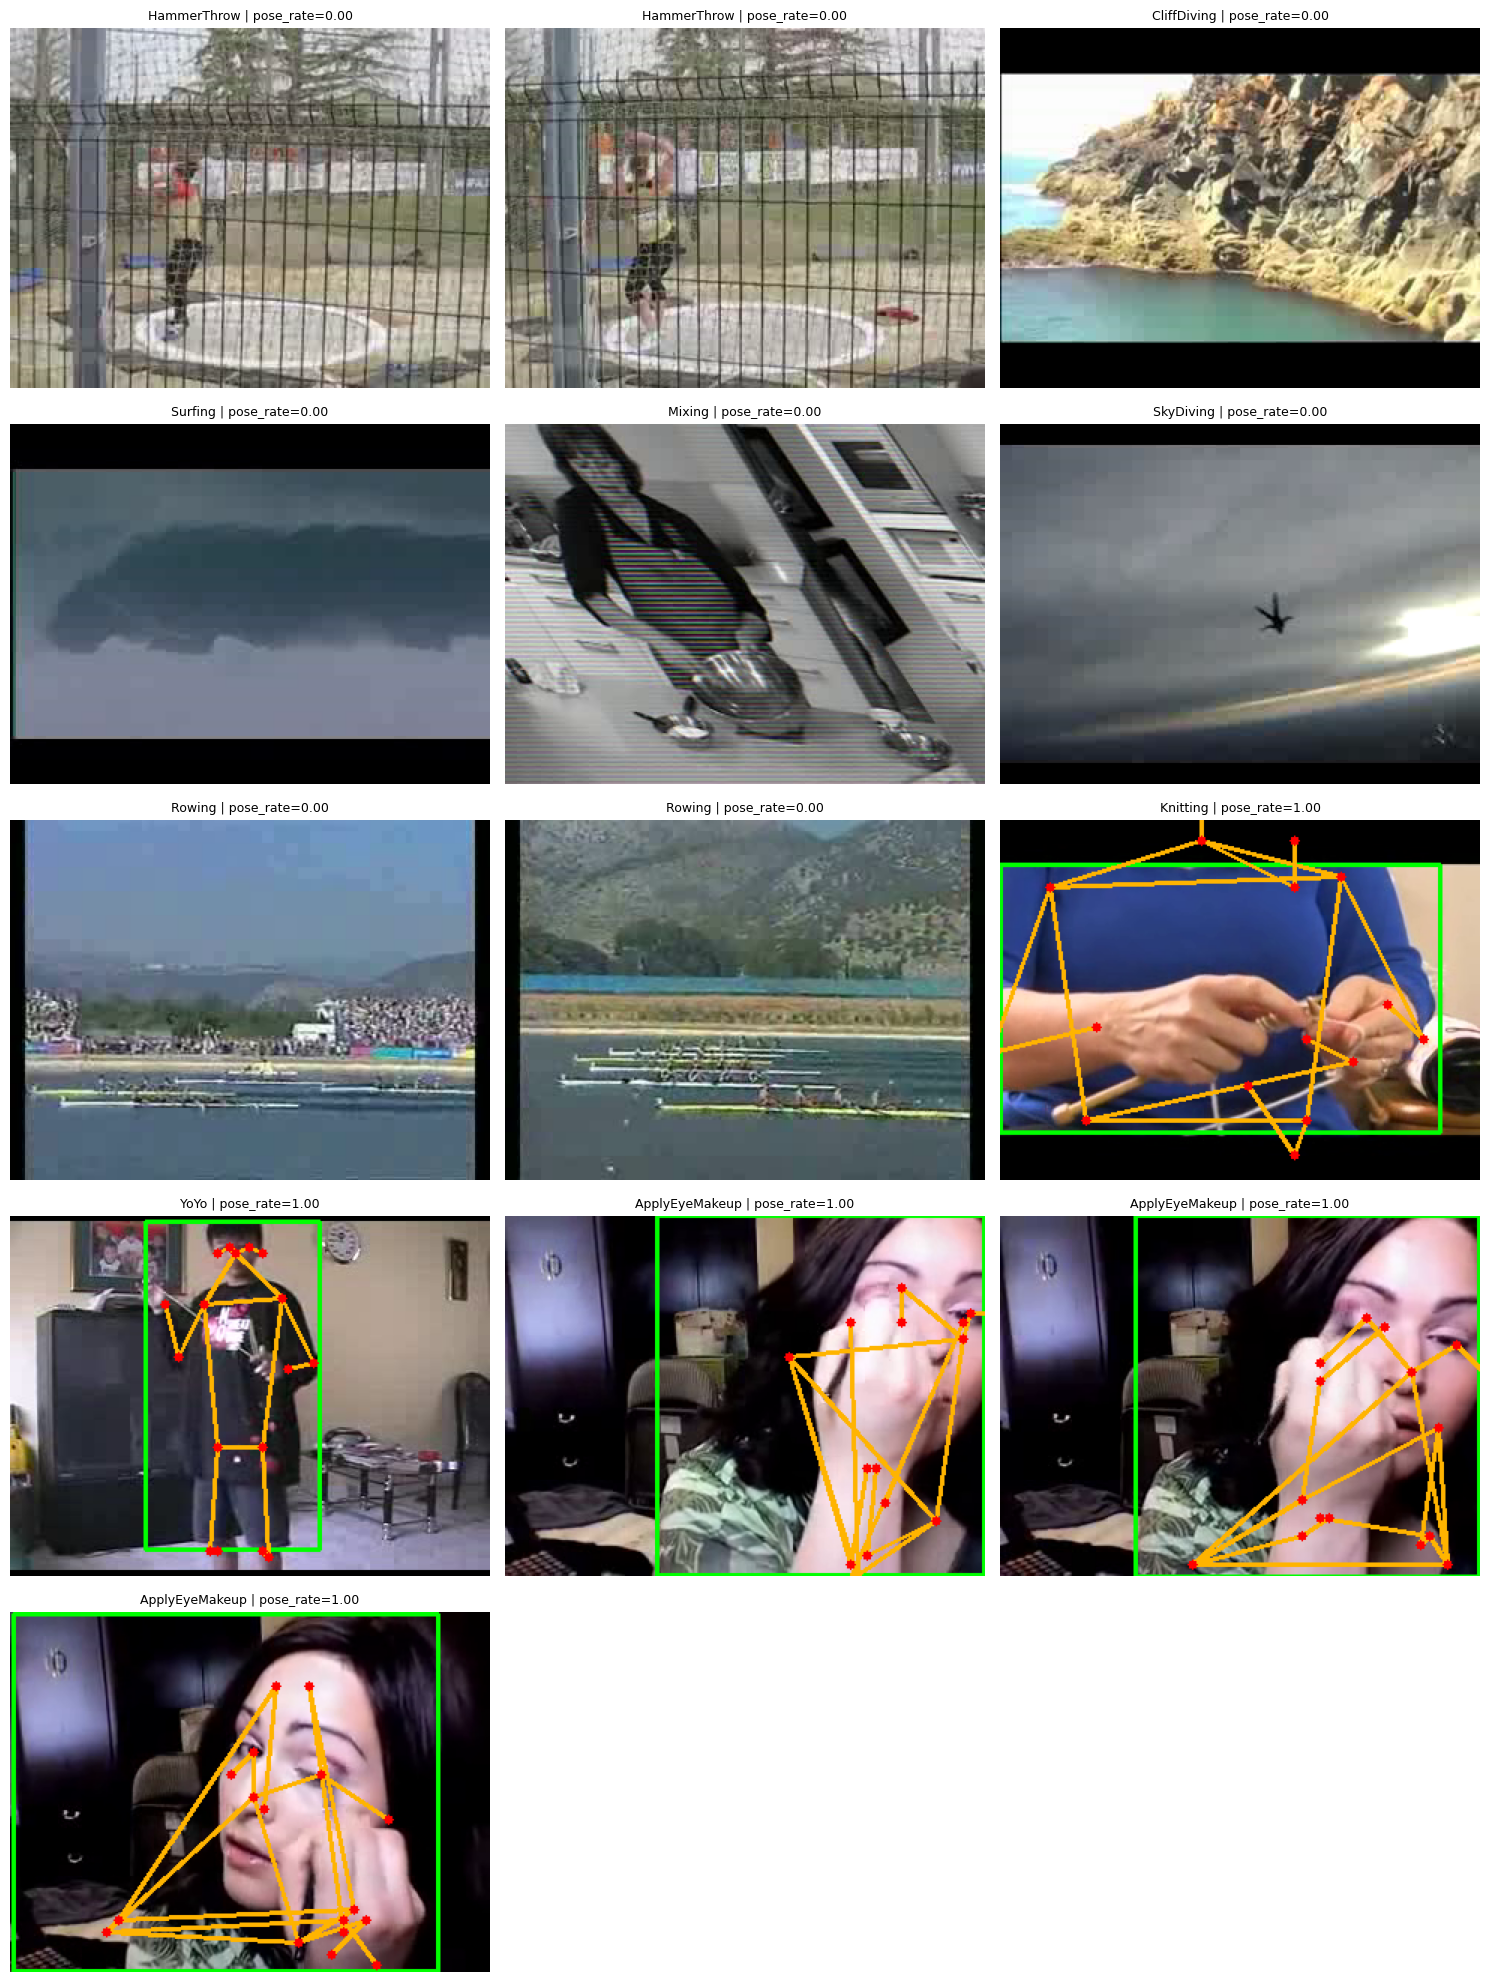

Contact sheet: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\visualizations\pose_quality_audit_v2\pose_quality_contact_sheet.png


In [3]:
COCO_EDGES = [(5,7),(7,9),(6,8),(8,10),(5,6),(5,11),(6,12),(11,12),(11,13),(13,15),(12,14),(14,16),(0,1),(0,2),(1,3),(2,4),(0,5),(0,6)]
def draw_pose(rgb, box, kp):
    canvas = rgb.copy()
    if np.isfinite(box).all():
        x1,y1,x2,y2 = map(int,box); cv2.rectangle(canvas,(x1,y1),(x2,y2),(0,255,0),2)
    for a,b in COCO_EDGES:
        if np.isfinite(kp[[a,b],:2]).all():
            pa=tuple(np.round(kp[a,:2]).astype(int)); pb=tuple(np.round(kp[b,:2]).astype(int))
            cv2.line(canvas,pa,pb,(255,180,0),2)
    for j in range(17):
        if np.isfinite(kp[j,:2]).all():
            x,y=np.round(kp[j,:2]).astype(int); cv2.circle(canvas,(x,y),3,(255,0,0),-1)
    return canvas

low = summary.sort_values("has_person_rate").head(8)
mid = summary.iloc[[len(summary)//2]]
high = summary.sort_values("has_person_rate", ascending=False).head(4)
selected = pd.concat([low,mid,high]).drop_duplicates("video_path").head(13)
imgs, titles = [], []
for _, row in selected.iterrows():
    try:
        with np.load(row["npz_path"],allow_pickle=False) as d:
            kps=np.asarray(d["keypoints"],dtype=np.float32); boxes=np.asarray(d["boxes"],dtype=np.float32)
            frame_indices=np.asarray(d["frame_indices"],dtype=np.int64); flags=np.asarray(d["has_person"],dtype=bool)
        candidates=np.flatnonzero(flags)
        idx=int(candidates[len(candidates)//2]) if len(candidates) else 0
        cap=cv2.VideoCapture(str(row["video_path"]))
        cap.set(cv2.CAP_PROP_POS_FRAMES,int(frame_indices[idx]))
        ok,bgr=cap.read(); cap.release()
        if not ok: continue
        imgs.append(draw_pose(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB),boxes[idx],kps[idx]))
        titles.append(f"{row['label']} | pose_rate={row['has_person_rate']:.2f}")
    except Exception as exc:
        print("Preview skipped:",Path(row["video_path"]).name,repr(exc))
if imgs:
    cols=3; nrows=(len(imgs)+cols-1)//cols
    fig,axes=plt.subplots(nrows,cols,figsize=(15,4*nrows)); axes=np.asarray(axes).reshape(-1)
    for ax,img,title in zip(axes,imgs,titles): ax.imshow(img); ax.set_title(title,fontsize=9); ax.axis("off")
    for ax in axes[len(imgs):]: ax.axis("off")
    plt.tight_layout(); out=VIS_DIR/"pose_quality_contact_sheet.png"; plt.savefig(out,dpi=130); plt.show()
    print("Contact sheet:",out)
else:
    print("No preview images could be generated.")

## Interpretation

`has_person_rate` is extraction coverage, not keypoint accuracy. A successful frame can still contain inaccurate joints. Use this audit to choose pilot videos and visually review the joints before changing thresholds or re-extracting the dataset.